# A curved sea floor in 3-D

`PropSEM(interfaces=...)` builds a Hex27 mesh whose element layers follow curved interfaces,
and `layered_model` gives each layer its material. A sea floor needs it: `BiotVSSEM3DDeformed`
models water (`biot_fluid`) and a dry rock (`biot_elastic`) in one mesh, coupled across the
faces between them, but each element has to be wholly one medium. With the mesh following the
sea floor, those faces are the sea floor itself.

1. The mesh: element layers following a seamount.
2. An air gun over the seamount, against a flat sea floor.

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt

from sweep.equations.biot_params import biot_elastic, biot_fluid
from sweep.sem import BiotVSSEM3DDeformed, PropSEM

DEV = "cuda" if torch.cuda.is_available() else "cpu"
print(f"device {DEV}")

device cuda


## 1. The mesh

A 600 m by 400 m area, 400 m deep, on 10 m grid steps (40 m elements at `n_order = 4`). The sea
floor lies 120 m deep and rises to 50 m over a seamount; the water gets three element layers and
the rock seven. The interfaces are given like `topography`, in rows of the model grid, one
`(ny, nx)` array each.

In [2]:
DH, NO, F0, DELAY = 10.0, 4, 15.0, 0.08
SHAPE, ABCN, DT, NT = (41, 41, 61), 16, 5e-4, 1200          # (nz, ny, nx), 0.6 s
ny, nx = SHAPE[1:]
yy, xx = np.meshgrid(np.arange(ny), np.arange(nx), indexing="ij")
seamount = 12.0 - 7.0 * np.exp(-((xx - 30.0) ** 2 + (yy - 20.0) ** 2) / (2 * 6.0 ** 2))
flat = np.full((ny, nx), 12.0)
WATER = biot_fluid(1020.0 * 1500.0 ** 2, 1020.0)
ROCK = biot_elastic(2400.0, 1300.0, 2000.0)


def solver(floor):
    return PropSEM(BiotVSSEM3DDeformed, shape=SHAPE, dh=DH, dt=DT, n_order=NO, abcn=ABCN,
                   free_surface=True, interfaces=[floor], interface_elements=[3, 7],
                   f_dominant=F0, dev=DEV, source_type=["p"], receiver_type=["vz", "p"])


p_sea, p_flat = solver(seamount), solver(flat)
print(f"{p_sea.mesh.n_elements} elements, impl {p_sea.impl}")

5796 elements, impl c


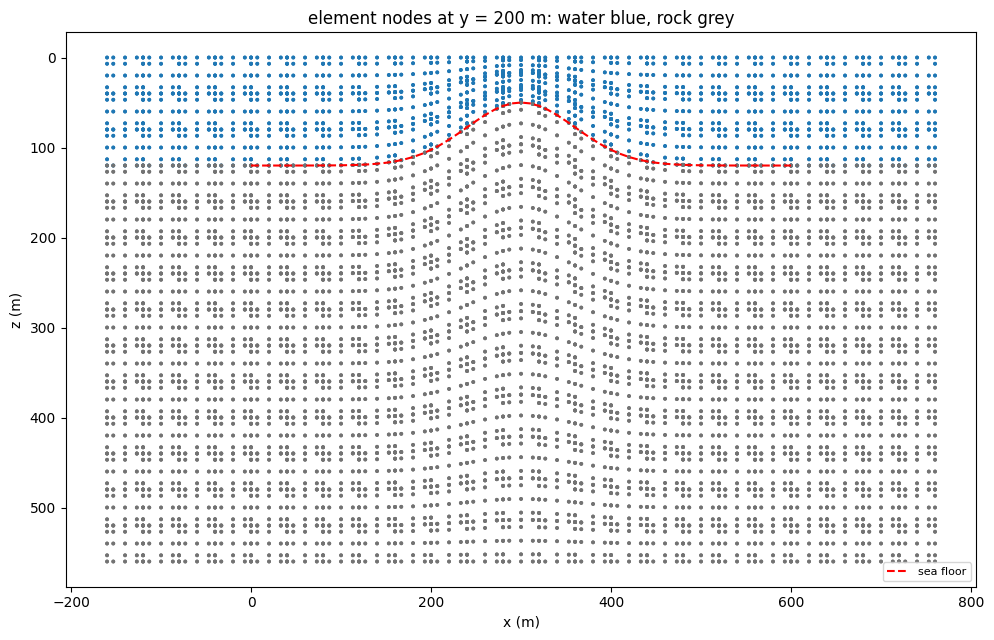

In [3]:
# the element nodes on the vertical plane through the seamount, y = 200 m; the mesh's
# coordinates include the absorbing layer, ABCN cells on each side (none on the free top)
mesh = p_sea.mesh
x_e, y_e, z_e = (c.cpu().numpy() for c in (mesh.x_e, mesh.y_e, mesh.z_e))
layer = np.broadcast_to(p_sea.element_layer.numpy().reshape(-1, 1, 1, 1), x_e.shape)
on = np.abs(y_e - (20 + ABCN) * DH) < 1e-6
xs = np.arange(nx) * DH

fig, ax = plt.subplots(figsize=(13, 6.5))
ax.scatter(x_e[on] - ABCN * DH, z_e[on], s=3, c=np.where(layer[on] == 0, "tab:blue", "0.45"))
ax.plot(xs, seamount[20] * DH, "r--", lw=1.5, label="sea floor")
ax.invert_yaxis()
ax.set_aspect("equal")
ax.set_xlabel("x (m)")
ax.set_ylabel("z (m)")
ax.set_title("element nodes at y = 200 m: water blue, rock grey")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
plt.show()

The element layers of the water and of the rock meet along the sea floor (dashed): the three
water layers thin over the seamount and the seven rock layers thicken under it. Outside
0-600 m and below 400 m is the absorbing layer, where the sea floor continues flat.

## 2. An air gun over the seamount

A pressure source 10 m deep above the seamount's flank, hydrophones 10 m deep, and geophones on
the sea floor (in the rock, just under it) along the line y = 200 m. The same run with a flat
sea floor shows what the seamount does to the records.

In [4]:
t = np.arange(NT) * DT
a = (np.pi * F0 * (t - DELAY)) ** 2
wav = ((1 - 2 * a) * np.exp(-a)).astype(np.float32)
src = np.array([[18.0, 20.0, 1.0]])
rx = np.arange(4.0, 57.0, 1.0)


def run(p, floor):
    models = [p.layered_model(c) for c in zip(WATER, ROCK)]
    hyd = np.stack([rx, np.full_like(rx, 20.0), np.full_like(rx, 1.0)], 1)
    obs = np.stack([rx, np.full_like(rx, 20.0), floor[20, rx.astype(int)] + 0.2], 1)
    rec = np.concatenate([hyd, obs])[None]
    with torch.no_grad():
        out = p(wav, src, rec, models=models)[0].cpu().numpy()
    n = len(rx)
    return out[:, :n, 1], out[:, n:, 0]          # hydrophone p, sea-floor vz


hyd_sea, obs_sea = run(p_sea, seamount)
hyd_flat, obs_flat = run(p_flat, flat)

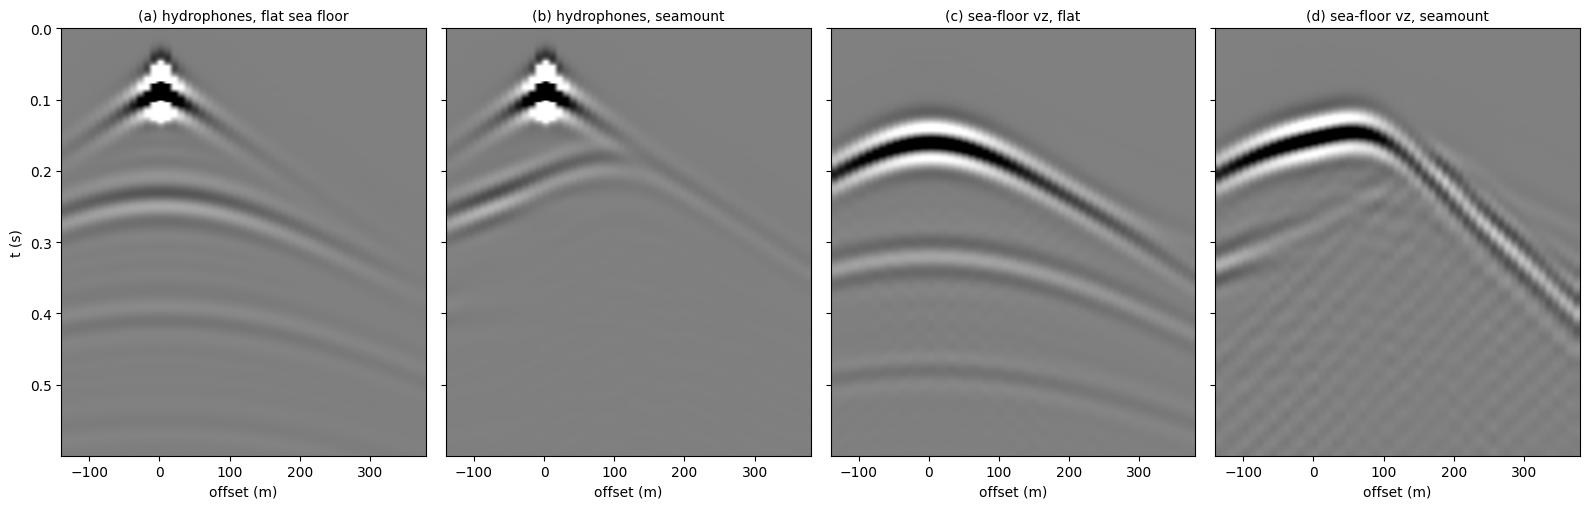

In [5]:
fig, ax = plt.subplots(1, 4, figsize=(16, 5.2), sharey=True)
off = (rx - src[0, 0]) * DH
panels = ((hyd_flat, "(a) hydrophones, flat sea floor"), (hyd_sea, "(b) hydrophones, seamount"),
          (obs_flat, "(c) sea-floor vz, flat"), (obs_sea, "(d) sea-floor vz, seamount"))
for a_, (data, lab) in zip(ax, panels):
    ref = hyd_flat if "hydrophones" in lab else obs_flat
    clip = np.percentile(np.abs(ref), 99)
    a_.imshow(data, aspect="auto", cmap="gray", vmin=-clip, vmax=clip,
              extent=[off[0], off[-1], t[-1], t[0]])
    a_.set_title(lab, fontsize=10)
    a_.set_xlabel("offset (m)")
ax[0].set_ylabel("t (s)")
fig.tight_layout()
plt.show()

Over the flat sea floor (a, c) the records hold the direct wave, the sea-floor reflection and
its multiples between the sea surface and the floor. Over the seamount (b) the reflection comes
earlier toward positive offsets, where the floor is shallower, and the multiples lose their
coherence. On the sea floor over the seamount (d) the first arrival comes earlier where the
geophones sit on its top, and the seamount scatters the waves that run along the floor.

---

<p><strong>Download this notebook</strong> &mdash; <a href="61_sem_seafloor3d.ipynb" download><code>61_sem_seafloor3d.ipynb</code></a> &middot; or <a href="https://github.com/DeepWave-KAUST/sweep/blob/dev/docs/notebooks/61_sem_seafloor3d.ipynb">view on GitHub</a></p>